### Investor access recommender

##### Paul Taiwo-Adeyemo, November 2026

### Introduction

This project looks at retail investment transactions and suggests assets a customer has not bought yet.

The data is FAR-Trans, trades from a Greek bank between 2018 and 2022. It is released by the University of Glasgow under CC-BY 4.0: https://doi.org/10.5525/gla.researchdata.1658

### Notebook #1

### Data cleaning and pre-processing

###### Order of analysis

>1. Load the transactions

>2. Check nulls and duplicate transaction ids

>3. Keep the buys

>4. Check how the buys are spread over the years, and which assets were bought most

>5. Export the cleaned buys as a csv for the next notebook

In this notebook the transactions are cleaned and checked before modelling.

In [1]:
#import the packages used for cleaning
import io
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
#same chart style for the plots in this notebook
plt.style.use("tableau-colorblind10")

#### Load the transactions

The csv is downloaded into `data/raw` if it is not already there. The other files in the zip are not used.

In [3]:
#download the csvs if they are not already here
raw = Path("data/raw")
raw.mkdir(parents=True, exist_ok=True)

if not (raw / "transactions.csv").exists():
    url = "https://researchdata.gla.ac.uk/1658/1/FAR-Trans.zip"
    with urllib.request.urlopen(url, timeout=120) as resp:
        payload = resp.read()
    with zipfile.ZipFile(io.BytesIO(payload)) as zf:
        for member in zf.infolist():
            name = Path(member.filename).name
            if name.endswith(".csv"):
                (raw / name).write_bytes(zf.read(member))

In [4]:
#load the transactions
transactions = pd.read_csv(raw / "transactions.csv")

In [5]:
#first rows
transactions.head()

,customerID,ISIN,transactionID,transactionType,timestamp,totalValue,units,channel,marketID
0,00017496858921195E5A,GRS434003000,7590224,Buy,2020-03-27,11000.0,5000.0,Internet Banking,XATH
1,00017496858921195E5A,GRS434003000,7607029,Sell,2020-04-06,12080.0,5000.0,Internet Banking,XATH
2,00017496858921195E5A,GRS434003000,7634872,Buy,2020-04-24,13400.0,5000.0,Internet Banking,XATH
3,00017496858921195E5A,GRS434003000,7652627,Sell,2020-05-07,12700.0,5000.0,Internet Banking,XATH
4,00017496858921195E5A,GRS434003000,7664807,Buy,2020-05-15,12150.0,5000.0,Internet Banking,XATH


In [6]:
#number of rows and columns
transactions.shape

(388048, 9)

The file has 388,048 rows and 9 columns. That is enough to see what customers tend to buy.

In [7]:
#column types
transactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 388048 entries, 0 to 388047
Data columns (total 9 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   customerID       388048 non-null  str    
 1   ISIN             388048 non-null  str    
 2   transactionID    388048 non-null  int64  
 3   transactionType  388048 non-null  str    
 4   timestamp        388048 non-null  str    
 5   totalValue       388048 non-null  float64
 6   units            388048 non-null  float64
 7   channel          388048 non-null  str    
 8   marketID         388048 non-null  str    
dtypes: float64(2), int64(1), str(6)
memory usage: 26.6 MB


In [8]:
#share of missing values in each column
transactions.isna().sum() / len(transactions) * 100

customerID         0.0
ISIN               0.0
transactionID      0.0
transactionType    0.0
timestamp          0.0
totalValue         0.0
units              0.0
channel            0.0
marketID           0.0
dtype: float64

There are no missing values.

In [9]:
#duplicate transaction ids
transactions["transactionID"].duplicated().sum()

np.int64(28920)

28,920 transaction ids show up more than once. One row is kept for each id, the one with the earlier date.

In [10]:
#keep the earlier row when a transaction id is repeated
transactions["timestamp"] = pd.to_datetime(transactions["timestamp"])
transactions = transactions.sort_values("timestamp")
transactions = transactions.drop_duplicates("transactionID", keep="first")
transactions["transactionID"].duplicated().sum()

np.int64(0)

#### Buys

Sells are not used. A suggestion is about what a customer might buy next.

In [11]:
#how many buys and sells are left
transactions["transactionType"].value_counts()

transactionType
Buy     213639
Sell    145489
Name: count, dtype: int64

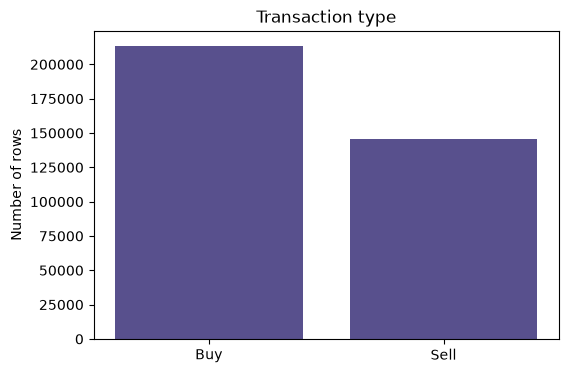

In [12]:
#plot buys and sells
type_counts = transactions["transactionType"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(type_counts.index, type_counts.values, color="#58508d")
plt.title("Transaction type")
plt.ylabel("Number of rows")
plt.show()

In [13]:
#keep the buys
buys = transactions[transactions["transactionType"] == "Buy"].copy()
buys.shape

(213639, 9)

213,639 buys are left, from 28,119 customers and 320 assets.

In [14]:
#customers and assets
buys["customerID"].nunique(), buys["ISIN"].nunique()

(28119, 320)

#### Buys by year

In [15]:
#buys in each year
buys_by_year = buys["timestamp"].dt.year.value_counts().sort_index()
buys_by_year

timestamp
2018    49329
2019    10609
2020    61045
2021    52486
2022    40170
Name: count, dtype: int64

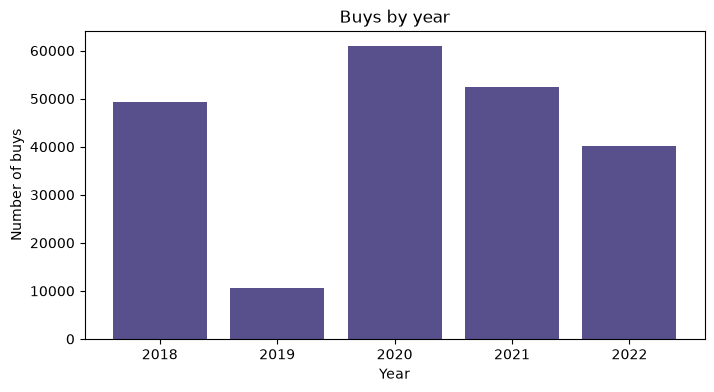

In [16]:
#plot buys by year
plt.figure(figsize=(8, 4))
plt.bar(buys_by_year.index.astype(str), buys_by_year.values, color="#58508d")
plt.title("Buys by year")
plt.xlabel("Year")
plt.ylabel("Number of buys")
plt.show()

2020 has the most buys. 2019 is much quieter than the other years.

#### Assets bought by the most customers

In [17]:
#number of customers who bought each asset
buyers = buys.groupby("ISIN")["customerID"].nunique().sort_values(ascending=False)
buyers.head(15)

ISIN
GRS003003035    8054
GRS015003007    4475
GRS260333000    3318
GRS014003032    2700
GRF000037009    2621
GRS323003012    2594
GRS434003000    2542
GRC5091217D9    2108
GRS298343005    2096
GRS393503008    2090
GRS419003009    2026
GRC4261213D5    1861
GRF000038007    1767
GRS495003006    1515
GRS518003009    1346
Name: customerID, dtype: int64

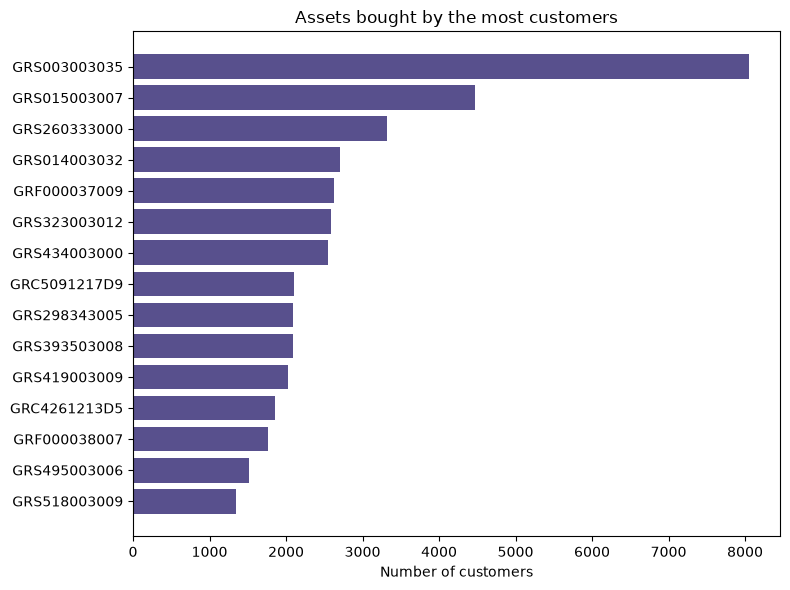

In [18]:
#plot the 15 assets with the most customers
top = buyers.head(15).sort_values()

plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color="#58508d")
plt.title("Assets bought by the most customers")
plt.xlabel("Number of customers")
plt.tight_layout()
plt.show()

A small number of assets were bought by a lot of customers. That is why a popularity list is a reasonable starting point in the next notebook.

In [19]:
#export the cleaned buys
out = Path("data/processed")
out.mkdir(parents=True, exist_ok=True)
buys[["customerID", "ISIN", "timestamp"]].to_csv(out / "buys.csv", index=False)

##### The work continues in Notebook #2. The modelling is done on the buys exported here.